HOUSE RENT (MULTIPLE LINEAR REGRESSION) part 1.3v(1.2v + area locality added(feature))

Data extraction , EDA and Data Processing

In [272]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [273]:
whole=pd.read_csv("House_Rent_Dataset.csv")

In [274]:
whole.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [275]:
whole

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [276]:
whole["Point of Contact"].value_counts()

Point of Contact
Contact Owner      3216
Contact Agent      1529
Contact Builder       1
Name: count, dtype: int64

In [277]:
whole["Rent_per_sqft"] = whole["Rent"] / whole["Size"]
whole.groupby("City")["Rent_per_sqft"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
City,,,,
Bangalore,886,21.751740,17.500000,47.911811
Chennai,891,19.785751,16.216216,23.885343
Delhi,605,67.631495,28.571429,90.467248
Hyderabad,868,23.585529,14.545455,70.550080
Kolkata,524,16.491473,13.315603,19.565843
Mumbai,972,81.668894,71.428571,41.495356


<Axes: xlabel='Rent_per_sqft'>

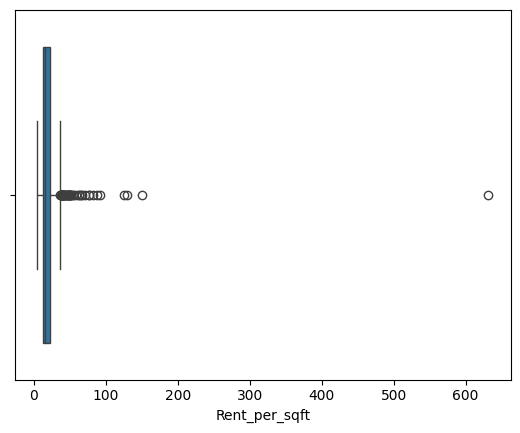

In [278]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])


Text(0.5, 1.0, 'Bangalore')

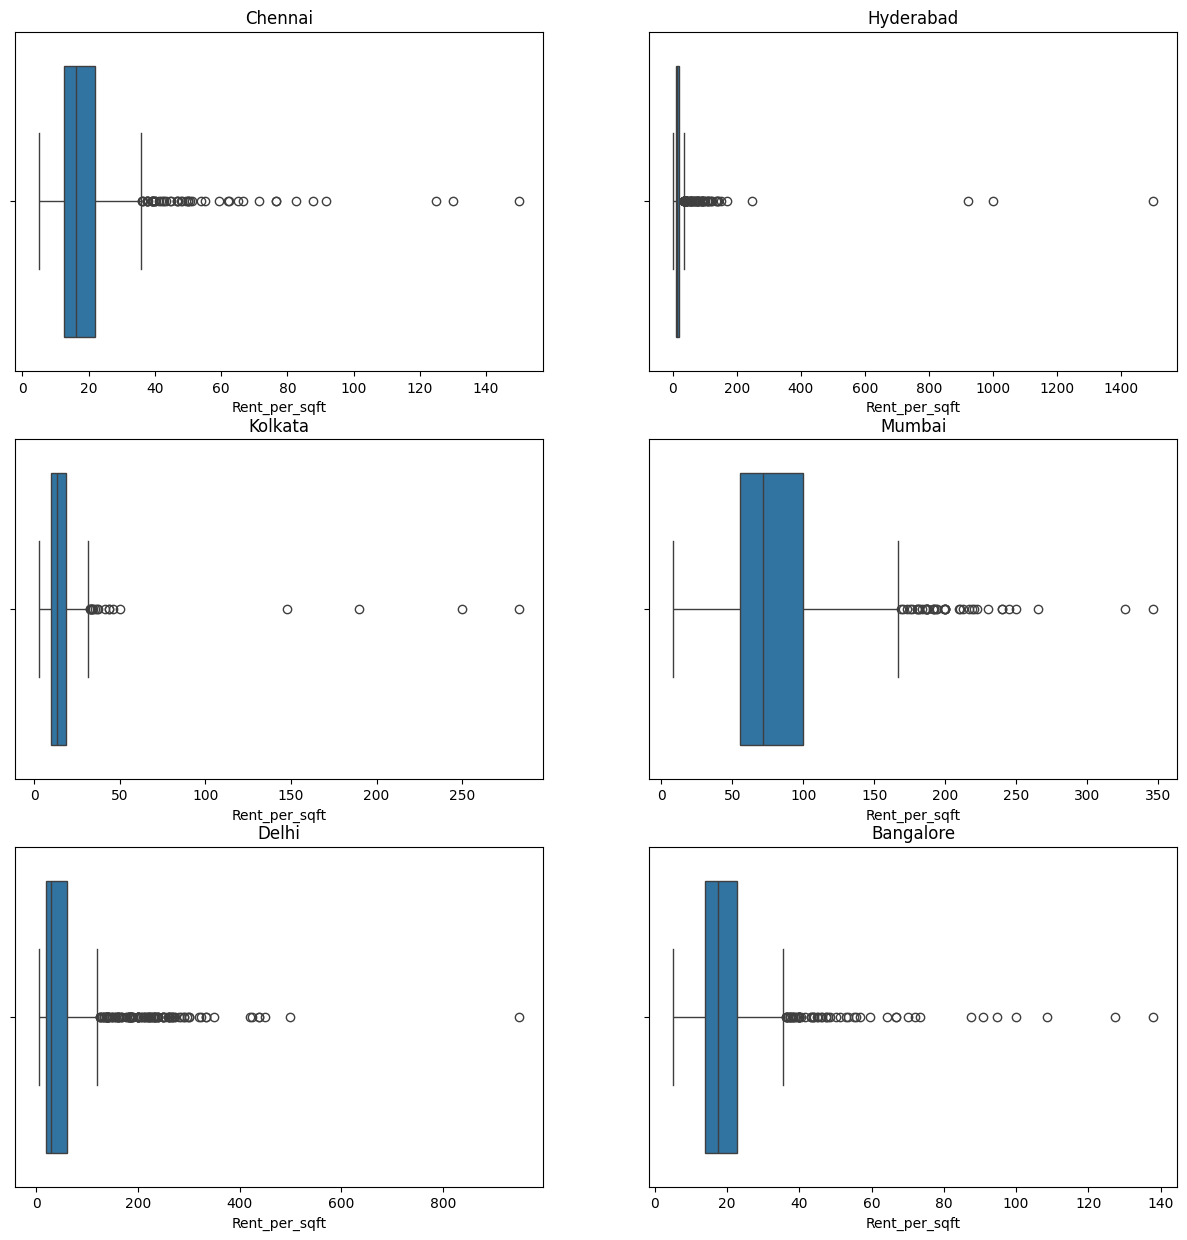

In [279]:
fig ,axes=plt.subplots(3,2,figsize=(15,15))

sns.boxplot(x=whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]<600)]["Rent_per_sqft"] ,ax=axes[0,0])
axes[0,0].set_title("Chennai")
sns.boxplot(x=whole[whole["City"]=="Hyderabad"]["Rent_per_sqft"] ,ax=axes[0,1])
axes[0,1].set_title("Hyderabad")
sns.boxplot(x=whole[whole["City"]=="Kolkata"]["Rent_per_sqft"] ,ax=axes[1,0])
axes[1,0].set_title("Kolkata")
sns.boxplot(x=whole[whole["City"]=="Mumbai"]["Rent_per_sqft"] ,ax=axes[1,1])
axes[1,1].set_title("Mumbai")
sns.boxplot(x=whole[whole["City"]=="Delhi"]["Rent_per_sqft"] ,ax=axes[2,0])
axes[2,0].set_title("Delhi")
sns.boxplot(x=whole[(whole["City"]=="Bangalore") & (whole["Rent_per_sqft"]<1200) ]["Rent_per_sqft"] ,ax=axes[2,1])
axes[2,1].set_title("Bangalore")

In [280]:
whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]>600)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3656,2022-07-06,2,600000,950,1 out of 1,Carpet Area,Vettuvankeni,Chennai,Unfurnished,Bachelors,2,Contact Owner,631.578947


In [281]:
whole.iloc[3656]


Posted On               2022-07-06
BHK                              2
Rent                        600000
Size                           950
Floor                   1 out of 1
Area Type              Carpet Area
Area Locality         Vettuvankeni
City                       Chennai
Furnishing Status      Unfurnished
Tenant Preferred         Bachelors
Bathroom                         2
Point of Contact     Contact Owner
Rent_per_sqft           631.578947
Name: 3656, dtype: object

In [282]:
whole.drop(index=3656,inplace=True) #already

<Axes: xlabel='Rent_per_sqft'>

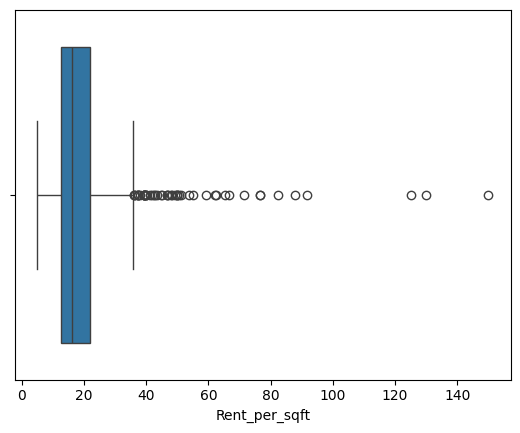

In [283]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])

In [284]:
whole_chennai=whole[whole["City"]=="Chennai"]

In [285]:
with pd.option_context('display.max_rows', None):
    print(whole_chennai["Area Locality"].value_counts())

Area Locality
Velachery                                                  22
Madipakkam                                                 20
Medavakkam                                                 17
Iyyappanthangal                                            17
Sholinganallur                                             16
Vadapalani                                                 15
Chromepet, GST Road                                        15
Ambattur                                                   14
Perungalathur, Chennai Bypass Road                         14
Old Mahabalipuram Road                                     13
Porur                                                      12
Choolaimedu                                                11
Kolathur                                                   11
Valasaravakkam, Arcot Road                                 11
Thiruvanmiyur                                              10
T Nagar                                                 

In [286]:
whole_chennai["Point of Contact"].value_counts()

Point of Contact
Contact Owner    756
Contact Agent    134
Name: count, dtype: int64

In [287]:
whole_chennai

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
2987,2022-07-06,2,15000,1100,1 out of 2,Super Area,Medavakkam,Chennai,Semi-Furnished,Bachelors,2,Contact Owner,13.636364
2988,2022-05-21,2,6500,1000,Ground out of 1,Super Area,"Urapakkam, Vandalur R.F, GST Road",Chennai,Semi-Furnished,Bachelors/Family,2,Contact Owner,6.500000
2989,2022-05-20,3,90000,2400,1 out of 3,Carpet Area,"R.A Puram, Mandaiveli",Chennai,Semi-Furnished,Bachelors/Family,3,Contact Agent,37.500000
2990,2022-07-10,3,200000,3000,1 out of 1,Super Area,Madras Boat Club Road,Chennai,Furnished,Family,4,Contact Agent,66.666667
2991,2022-06-25,1,15000,650,Ground out of 2,Carpet Area,Kambar Colony,Chennai,Semi-Furnished,Bachelors/Family,1,Contact Owner,23.076923
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3873,2022-07-10,3,28000,1050,5 out of 10,Carpet Area,Pallavaram,Chennai,Semi-Furnished,Bachelors/Family,3,Contact Agent,26.666667
3874,2022-06-22,2,10677,800,5 out of 6,Super Area,"Kelambakkam, Old Mahabalipuram Road",Chennai,Semi-Furnished,Bachelors/Family,2,Contact Owner,13.346250
3875,2022-07-01,3,50000,1625,8 out of 11,Super Area,Old Mahabalipuram Road,Chennai,Furnished,Bachelors/Family,3,Contact Agent,30.769231
3876,2022-06-17,3,32500,1535,1 out of 2,Super Area,Karapakkam,Chennai,Unfurnished,Bachelors/Family,3,Contact Agent,21.172638


feature extraction

In [288]:
#df=whole_chennai[["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]]
#df.describe()
#df.info()
#df.shape

In [289]:
cats = [ "Tenant Preferred", "Point of Contact"]   # columns to convert
features=["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]
whole_chennai = whole_chennai.copy()
#whole_chennai["Area Type"] = whole_chennai["Area Type"].replace("Built Area", "Super Area")  # merge the 1-row category

X_new = pd.get_dummies(
    whole_chennai[features + cats],   # your 6 numeric columns + the 3 text columns
    columns=cats,            # only encode these 3; numeric columns pass through unchanged
    drop_first=True,         # drop one column per category (the reference)
    dtype=float              # 0.0/1.0 instead of True/False
)
print(X_new.columns.tolist())

['BHK', 'Size', 'Floor', 'Furnishing Status', 'Bathroom', 'Rent', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Point of Contact_Contact Owner']


In [290]:
df =X_new.copy()

In [291]:
df

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
2987,2,1100,1 out of 2,Semi-Furnished,2,15000,0.0,0.0,1.0
2988,2,1000,Ground out of 1,Semi-Furnished,2,6500,1.0,0.0,1.0
2989,3,2400,1 out of 3,Semi-Furnished,3,90000,1.0,0.0,0.0
2990,3,3000,1 out of 1,Furnished,4,200000,0.0,1.0,0.0
2991,1,650,Ground out of 2,Semi-Furnished,1,15000,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
3873,3,1050,5 out of 10,Semi-Furnished,3,28000,1.0,0.0,0.0
3874,2,800,5 out of 6,Semi-Furnished,2,10677,1.0,0.0,1.0
3875,3,1625,8 out of 11,Furnished,3,50000,1.0,0.0,0.0
3876,3,1535,1 out of 2,Unfurnished,3,32500,1.0,0.0,0.0


In [292]:
df = df.sample(frac=1, random_state=42)

In [293]:
df["Furnishing Status"] = df["Furnishing Status"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})
df.head()

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
3267,2,650,2 out of 2,2,2,17500,1.0,0.0,1.0
3421,3,1300,19 out of 19,2,3,30000,1.0,0.0,1.0
3026,2,850,Ground out of 2,0,2,12000,0.0,1.0,1.0
3404,1,500,1 out of 4,0,1,18000,1.0,0.0,1.0
3572,2,1000,1 out of 2,0,2,18000,1.0,0.0,1.0


In [294]:
df['Floor_no.']=df["Floor"].str.extract(r"^(\d+)")

In [295]:
df["Floor_no."].value_counts()

Floor_no.
1     321
2     164
3      59
4      30
9      13
5      11
7      10
8       7
10      6
15      6
11      6
6       5
12      3
17      2
19      2
20      1
16      1
25      1
13      1
24      1
28      1
14      1
Name: count, dtype: int64

In [296]:
df.loc[df["Floor"].str.startswith("Ground", na=False),"Floor_no."] = 0

df.loc[df["Floor"].str.startswith("Upper Basement", na=False),"Floor_no."] = -1

df.loc[df["Floor"].str.startswith("Lower Basement", na=False),"Floor_no."] = -2

In [297]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 3267 to 3089
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   BHK                                890 non-null    int64  
 1   Size                               890 non-null    int64  
 2   Floor                              890 non-null    object 
 3   Furnishing Status                  890 non-null    int64  
 4   Bathroom                           890 non-null    int64  
 5   Rent                               890 non-null    int64  
 6   Tenant Preferred_Bachelors/Family  890 non-null    float64
 7   Tenant Preferred_Family            890 non-null    float64
 8   Point of Contact_Contact Owner     890 non-null    float64
 9   Floor_no.                          890 non-null    object 
dtypes: float64(3), int64(5), object(2)
memory usage: 76.5+ KB


In [298]:
df["Floor_no."] = df["Floor_no."].astype(float)

In [299]:
df.drop(columns=["Floor"],inplace=True)

In [300]:
df[df["Floor_no."]==-1].value_counts()

BHK  Size  Furnishing Status  Bathroom  Rent  Tenant Preferred_Bachelors/Family  Tenant Preferred_Family  Point of Contact_Contact Owner  Floor_no.
1    400   0                  1         8000  1.0                                0.0                      1.0                             -1.0         1
Name: count, dtype: int64

In [301]:
cols = df.columns.tolist()
cols.remove('Rent')
cols.append('Rent')

df = df[cols]
df.head()

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Rent
3267,2,650,2,2,1.0,0.0,1.0,2.0,17500
3421,3,1300,2,3,1.0,0.0,1.0,19.0,30000
3026,2,850,0,2,0.0,1.0,1.0,0.0,12000
3404,1,500,0,1,1.0,0.0,1.0,1.0,18000
3572,2,1000,0,2,1.0,0.0,1.0,1.0,18000


<Axes: >

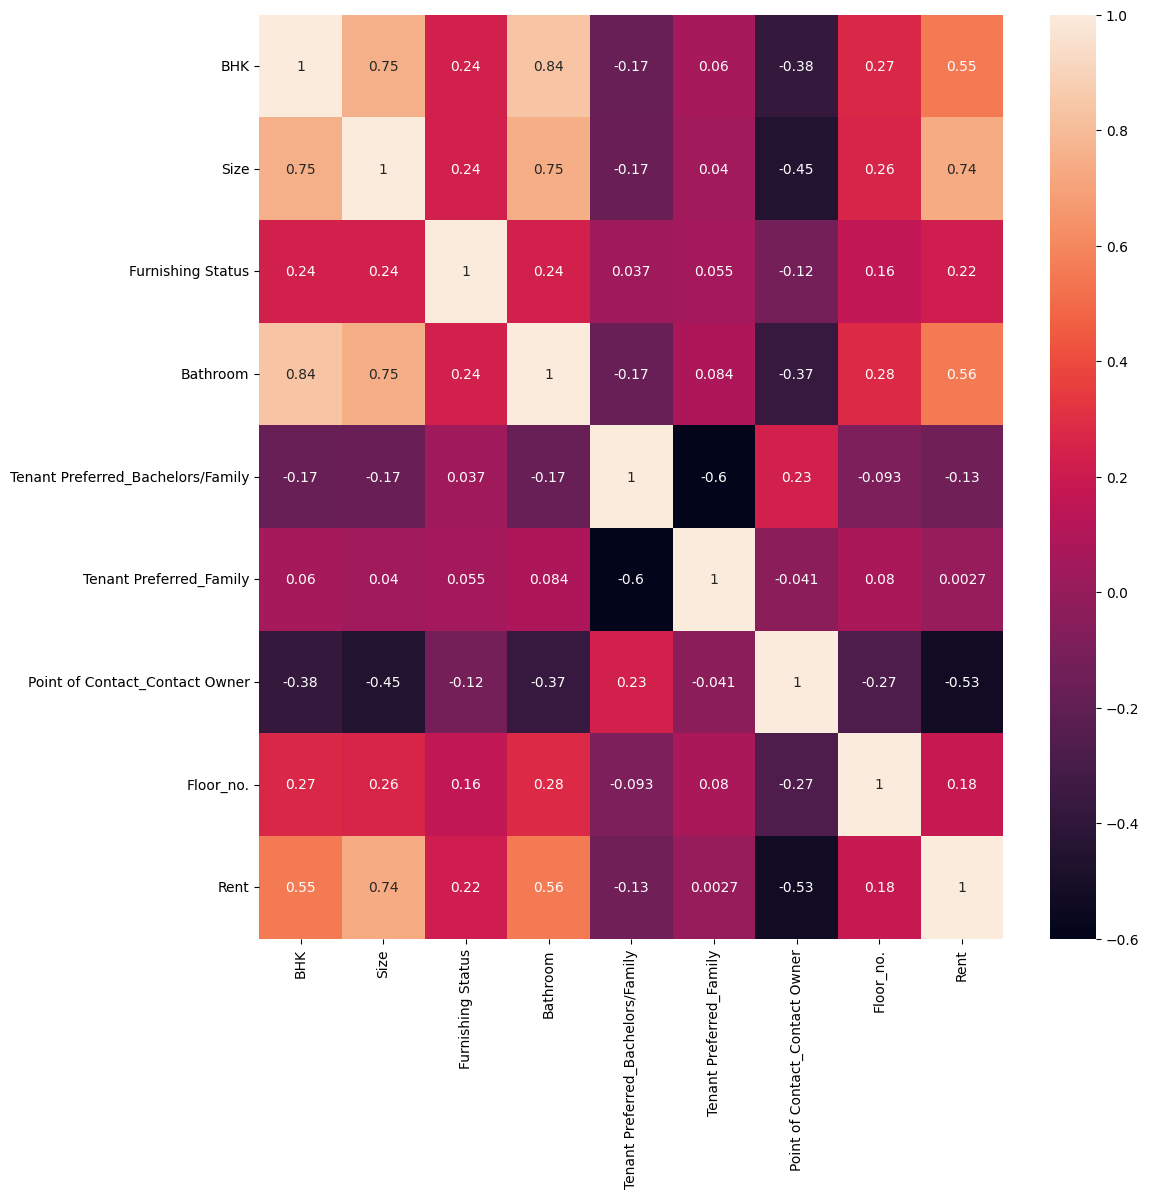

In [302]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(numeric_only=True), annot=True)

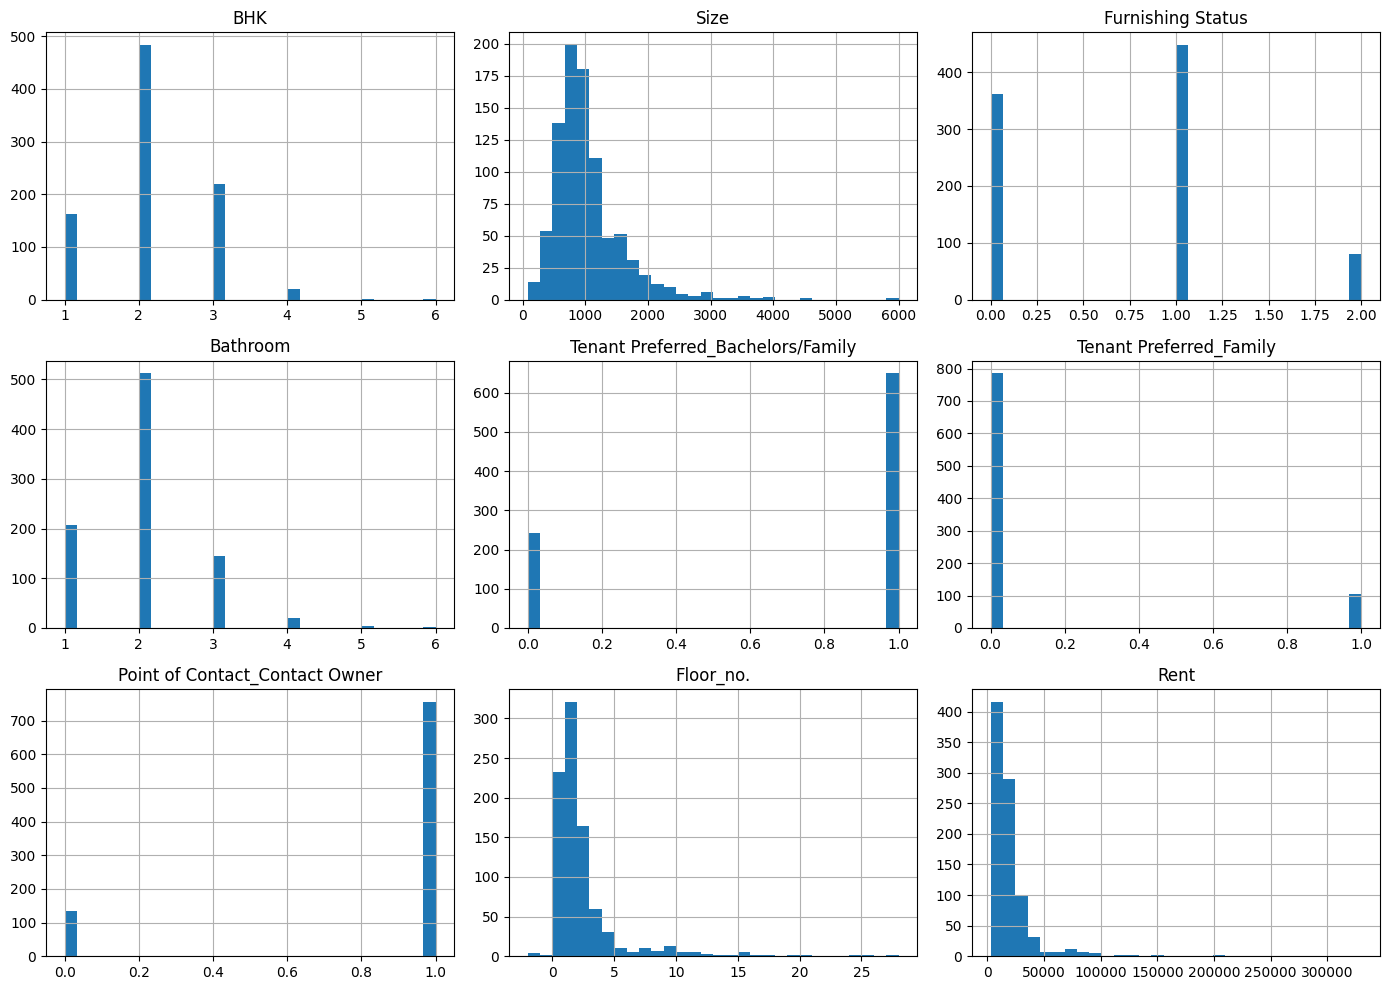

In [303]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()

plt.show()

In [304]:
df_c=df[df["Rent"]<100000]

In [305]:
df_c

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Rent
3267,2,650,2,2,1.0,0.0,1.0,2.0,17500
3421,3,1300,2,3,1.0,0.0,1.0,19.0,30000
3026,2,850,0,2,0.0,1.0,1.0,0.0,12000
3404,1,500,0,1,1.0,0.0,1.0,1.0,18000
3572,2,1000,0,2,1.0,0.0,1.0,1.0,18000
...,...,...,...,...,...,...,...,...,...
3093,2,850,0,2,1.0,0.0,1.0,0.0,24000
3257,2,900,2,2,1.0,0.0,1.0,2.0,14000
3848,3,1500,0,3,0.0,0.0,0.0,2.0,27000
3422,3,1484,1,3,1.0,0.0,0.0,9.0,30000


In [306]:
X_new=df_c.drop("Rent",axis=1)


In [308]:
def group_location(x):
    x = str(x).lower().strip()

    # 1. Velachery
    if "velachery" in x:
        return "Velachery"

    # 2. Madipakkam - Pallikaranai
    elif any(k in x for k in [
        "madipakkam", "pallikaranai", "kovilambakkam",
        "keelkattalai", "puzhuthivakkam"
    ]):
        return "Madipakkam-Pallikaranai"

    # 3. Medavakkam - Selaiyur
    elif any(k in x for k in [
        "medavakkam", "selaiyur", "sembakkam",
        "vengaivasal", "santhosapuram", "rajakilpakkam"
    ]):
        return "Medavakkam-Selaiyur"

    # 4. Tambaram - Perungalathur
    elif any(k in x for k in [
        "tambaram", "perungalathur", "mudichur",
        "irumbuliyur"
    ]):
        return "Tambaram-Perungalathur"

    # 5. Chromepet - Pallavaram
    elif any(k in x for k in [
        "chromepet", "chrompet", "pallavaram",
        "zamin pallavaram"
    ]):
        return "Chromepet-Pallavaram"

    # 6. OMR
    elif any(k in x for k in [
        "sholinganallur", "thoraipakkam", "navalur",
        "padur", "kelambakkam", "siruseri",
        "thalambur", "semmancheri", "semmenchery",
        "karapakkam", "okkiyam", "kazhipattur",
        "thiruporur"
    ]):
        return "OMR"

    # 7. ECR
    elif any(k in x for k in [
        "e coast", "ecr", "east coast",
        "thiruvanmiyur", "neelankarai", "palavakkam",
        "injambakkam", "uthandi", "panaiyur",
        "kanathur"
    ]):
        return "ECR"

    # 8. Adyar - Besant Nagar
    elif any(k in x for k in [
        "adyar", "besant nagar", "r.a puram",
        "mandaiveli", "kasturibai"
    ]):
        return "Adyar-Besant Nagar"

    # 9. Mylapore - Teynampet
    elif any(k in x for k in [
        "mylapore", "abiramapuram", "luz",
        "teynampet", "nandanam", "poes garden"
    ]):
        return "Mylapore-Teynampet"

    # 10. T Nagar - Mambalam
    elif any(k in x for k in [
        "t nagar", "t.nagar", "mambalam",
        "cit nagar"
    ]):
        return "T-Nagar-Mambalam"

    # 11. Anna Nagar
    elif any(k in x for k in [
        "anna nagar", "annanagar", "thirumangalam"
    ]):
        return "Anna Nagar"

    # 12. Central Chennai
    elif any(k in x for k in [
        "egmore", "chetpet", "kilpauk", "purasawalkam",
        "purasaiwakkam", "royapettah", "triplicane",
        "chintadripet", "periyamet", "shenoy nagar"
    ]):
        return "Central Chennai"

    # 13. Porur - Valasaravakkam
    elif any(k in x for k in [
        "porur", "mugalivakkam", "manapakkam",
        "valasaravakkam", "virugambakkam",
        "alwarthirunagar", "ramapuram"
    ]):
        return "Porur-Valasaravakkam"

    # 14. Ambattur - Avadi
    elif any(k in x for k in [
        "ambattur", "ayappakkam", "ayappa nagar",
        "menambedu", "avadi", "thirumullaivoyal",
        "pattabiram"
    ]):
        return "Ambattur-Avadi"

    # 15. Mogappair - Koyambedu
    elif any(k in x for k in [
        "mogappair", "koyambedu", "arumbakkam",
        "aminjikarai"
    ]):
        return "Mogappair-Koyambedu"

    # 16. Kolathur - Perambur
    elif any(k in x for k in [
        "kolathur", "perambur", "ayanavaram",
        "villivakkam", "jawahar nagar"
    ]):
        return "Kolathur-Perambur"

    # 17. North Chennai
    elif any(k in x for k in [
        "madhavaram", "kodungaiyur", "tondiarpet",
        "washermanpet", "tiruvottiyur", "ennore",
        "manali", "redhills"
    ]):
        return "North Chennai"

    # 18. Outer West/South
    elif any(k in x for k in [
        "poonamallee", "poonamalle", "mangadu",
        "kundrathur", "thiruverkkadu", "vandalur",
        "urapakkam", "guduvancheri", "oragadam",
        "sriperumbudur", "mahindra city", "mahindra world city"
    ]):
        return "Outer West-South"

    # Everything else
    else:
        return "Other"

In [309]:
loc=whole_chennai[whole_chennai["Rent"]<100000]["Area Locality"]
X_loc=X_new.copy()
X_loc["Location_Group"]=loc

X_loc.head()

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Location_Group
3267,2,650,2,2,1.0,0.0,1.0,2.0,Thiruvanmiyur
3421,3,1300,2,3,1.0,0.0,1.0,19.0,Navalur
3026,2,850,0,2,0.0,1.0,1.0,0.0,Perambur
3404,1,500,0,1,1.0,0.0,1.0,1.0,"George Town, PH Road"
3572,2,1000,0,2,1.0,0.0,1.0,1.0,Sholinganallur


In [310]:
#floc=['Other','Tambaram','Chromepet/Pallavaram','Porur/Valasaravakkam','Velachery','Madipakkam','Medavakkam','Anna Nagar']
#X_loc=X_loc.drop(columns=floc,axis=1)
X_loc

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Location_Group
3267,2,650,2,2,1.0,0.0,1.0,2.0,Thiruvanmiyur
3421,3,1300,2,3,1.0,0.0,1.0,19.0,Navalur
3026,2,850,0,2,0.0,1.0,1.0,0.0,Perambur
3404,1,500,0,1,1.0,0.0,1.0,1.0,"George Town, PH Road"
3572,2,1000,0,2,1.0,0.0,1.0,1.0,Sholinganallur
...,...,...,...,...,...,...,...,...,...
3093,2,850,0,2,1.0,0.0,1.0,0.0,Mylapore
3257,2,900,2,2,1.0,0.0,1.0,2.0,"Ram Nagar South Extension, Madipakkam"
3848,3,1500,0,3,0.0,0.0,0.0,2.0,Perungudi
3422,3,1484,1,3,1.0,0.0,0.0,9.0,Porur


In [311]:

X_loc["Location_Group"] = X_loc["Location_Group"].apply(group_location)
X_loc["Location_Group"].value_counts()

Location_Group
Other                      296
OMR                         67
Porur-Valasaravakkam        51
Madipakkam-Pallikaranai     44
Outer West-South            43
Tambaram-Perungalathur      38
Medavakkam-Selaiyur         38
Kolathur-Perambur           35
Chromepet-Pallavaram        34
Velachery                   29
Ambattur-Avadi              27
Central Chennai             26
North Chennai               23
ECR                         22
Adyar-Besant Nagar          22
Anna Nagar                  20
Mogappair-Koyambedu         20
T-Nagar-Mambalam            18
Mylapore-Teynampet          16
Name: count, dtype: int64

In [312]:
X_loc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 869 entries, 3267 to 3089
Data columns (total 9 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   BHK                                869 non-null    int64  
 1   Size                               869 non-null    int64  
 2   Furnishing Status                  869 non-null    int64  
 3   Bathroom                           869 non-null    int64  
 4   Tenant Preferred_Bachelors/Family  869 non-null    float64
 5   Tenant Preferred_Family            869 non-null    float64
 6   Point of Contact_Contact Owner     869 non-null    float64
 7   Floor_no.                          869 non-null    float64
 8   Location_Group                     869 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 67.9+ KB


In [313]:
#X_loc["Location_Group"]=['Other','Tambaram','Chromepet/Pallavaram','Porur/Valasaravakkam','Velachery','Madipakkam','Medavakkam','Anna Nagar']
X_loc=pd.get_dummies(X_loc,columns=["Location_Group"],dtype=int)

In [314]:
X_loc

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Location_Group_Adyar-Besant Nagar,Location_Group_Ambattur-Avadi,...,Location_Group_Mogappair-Koyambedu,Location_Group_Mylapore-Teynampet,Location_Group_North Chennai,Location_Group_OMR,Location_Group_Other,Location_Group_Outer West-South,Location_Group_Porur-Valasaravakkam,Location_Group_T-Nagar-Mambalam,Location_Group_Tambaram-Perungalathur,Location_Group_Velachery
3267,2,650,2,2,1.0,0.0,1.0,2.0,0,0,...,0,0,0,0,0,0,0,0,0,0
3421,3,1300,2,3,1.0,0.0,1.0,19.0,0,0,...,0,0,0,1,0,0,0,0,0,0
3026,2,850,0,2,0.0,1.0,1.0,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
3404,1,500,0,1,1.0,0.0,1.0,1.0,0,0,...,0,0,0,0,1,0,0,0,0,0
3572,2,1000,0,2,1.0,0.0,1.0,1.0,0,0,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3093,2,850,0,2,1.0,0.0,1.0,0.0,0,0,...,0,1,0,0,0,0,0,0,0,0
3257,2,900,2,2,1.0,0.0,1.0,2.0,0,0,...,0,0,0,0,0,0,0,0,0,0
3848,3,1500,0,3,0.0,0.0,0.0,2.0,0,0,...,0,0,0,0,1,0,0,0,0,0
3422,3,1484,1,3,1.0,0.0,0.0,9.0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [315]:
df_c = df[df["Rent"] < 100000].copy()

X_new=df_c.drop("Rent",axis=1)

In [333]:
X_new.columns.tolist()

['BHK',
 'Size',
 'Furnishing Status',
 'Bathroom',
 'Tenant Preferred_Bachelors/Family',
 'Tenant Preferred_Family',
 'Point of Contact_Contact Owner',
 'Floor_no.']

for verification of gradient descent (as for low no. of rows nosie increases)

In [327]:
X_log_size=X_new.copy()
size=X_log_size["Size"]
X_log_size["Size"]=np.log(size)

In [335]:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score

y_all = df_c["Rent"].values          # rent in rupees
y_log_all = np.log(y_all)            # log target, same as your GD

kf = KFold(5, shuffle=True, random_state=42)   # the 5-fold splitter

def cv_score(Xdf, name):
    # for each row, predict using a model trained on the other 4 folds
    pred_log = cross_val_predict(LinearRegression(), Xdf, y_log_all, cv=kf)
    print(f"{name:22s} log R2={r2_score(y_log_all, pred_log):.4f}  "
          f"MAE(rupees)={mean_absolute_error(y_all, np.exp(pred_log)):.0f}")

cv_score(X_new, "'BHK','Size','Furnishing Status','Bathroom','Tenant Preferred_Bachelors/Family','Tenant Preferred_Family','Point of Contact_Contact Owner','Floor_no.'")             # the one-hot version
cv_score(X_log_size, "for log of size")
cv_score(X_loc, "added locality")

'BHK','Size','Furnishing Status','Bathroom','Tenant Preferred_Bachelors/Family','Tenant Preferred_Family','Point of Contact_Contact Owner','Floor_no.' log R2=0.6804  MAE(rupees)=4700
for log of size        log R2=0.6748  MAE(rupees)=4684
added locality         log R2=0.7365  MAE(rupees)=4363


In [317]:
from sklearn.ensemble import GradientBoostingRegressor
pred_log = cross_val_predict(GradientBoostingRegressor(random_state=42), X_loc, y_log_all, cv=kf)
print(r2_score(y_log_all, pred_log), mean_absolute_error(y_all, np.exp(pred_log)))

0.7388635596231466 4155.361219460281


In [318]:
df_loc=X_loc.copy()
df_loc["Rent"]=df_c["Rent"]

In [319]:
df_loc

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Location_Group_Adyar-Besant Nagar,Location_Group_Ambattur-Avadi,...,Location_Group_Mylapore-Teynampet,Location_Group_North Chennai,Location_Group_OMR,Location_Group_Other,Location_Group_Outer West-South,Location_Group_Porur-Valasaravakkam,Location_Group_T-Nagar-Mambalam,Location_Group_Tambaram-Perungalathur,Location_Group_Velachery,Rent
3267,2,650,2,2,1.0,0.0,1.0,2.0,0,0,...,0,0,0,0,0,0,0,0,0,17500
3421,3,1300,2,3,1.0,0.0,1.0,19.0,0,0,...,0,0,1,0,0,0,0,0,0,30000
3026,2,850,0,2,0.0,1.0,1.0,0.0,0,0,...,0,0,0,0,0,0,0,0,0,12000
3404,1,500,0,1,1.0,0.0,1.0,1.0,0,0,...,0,0,0,1,0,0,0,0,0,18000
3572,2,1000,0,2,1.0,0.0,1.0,1.0,0,0,...,0,0,1,0,0,0,0,0,0,18000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3093,2,850,0,2,1.0,0.0,1.0,0.0,0,0,...,1,0,0,0,0,0,0,0,0,24000
3257,2,900,2,2,1.0,0.0,1.0,2.0,0,0,...,0,0,0,0,0,0,0,0,0,14000
3848,3,1500,0,3,0.0,0.0,0.0,2.0,0,0,...,0,0,0,1,0,0,0,0,0,27000
3422,3,1484,1,3,1.0,0.0,0.0,9.0,0,0,...,0,0,0,0,0,1,0,0,0,30000


In [320]:
# Find the split point

split = int(0.8 * len(df_loc))

# Split

train_df = df_loc.iloc[:split]

test_df = df_loc.iloc[split:]

In [321]:

X_train, y_train = train_df .drop("Rent" ,axis=1), train_df["Rent"]
X_test,  y_test  = test_df.drop("Rent",axis=1), test_df["Rent"]


In [322]:
#import numpy as np

# ---------- NEW: log-transform the target ----------
y_train_log = np.log(y_train)   # CHANGED
y_test_log  = np.log(y_test)    # CHANGED

# ----------  Z-score scaling (stats from TRAIN only) ----------
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)

X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

# ----------  Gradient descent ----------
def gradient_descent(x, y, lr=0.01, epochs=2500):
    n_features = x.shape[1]
    w = np.zeros(n_features)
    b = 0
    m = len(x)

    history = []
    for i in range(epochs):
        y_pred = np.dot(x, w) + b
        error = y_pred - y
        dw = (1 / m) * np.dot(x.T, error)
        db = (1 / m) * np.sum(error)

        w -= lr * dw
        b -= lr * db
        history.append((1 / (2 * m)) * np.sum(error ** 2))
        if i % 200 == 0:
            print(f"epoch {i:4d}  cost = {history[-1]:.6f}")   # CHANGED: cost is now small, need more decimals
    return w, b, history

w, b, cost_history = gradient_descent(X_train_s, y_train_log)   # CHANGED: train on log(rent)

print(f"\nLearned weights (scaled space):")
print(w)
print(f"Bias (scaled space): {b:.4f}")                          # CHANGED: bias is ~9-10 now

w_orig = w / sigma
b_orig = b - np.sum(w * mu / sigma)
print("In original units (effect on log-rent):")
print("w =\n", w_orig)
print("b =", b_orig)

# ----------  Evaluation metrics ----------
def evaluate(y_true, y_pred):
    mse  = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

# CHANGED: predictions are in log space, convert back with exp
train_pred_log = np.dot(X_train_s, w) + b
test_pred_log  = np.dot(X_test_s, w) + b
train_pred = np.exp(train_pred_log)
test_pred  = np.exp(test_pred_log)

print("\n--- Rupee scale (compare with your old 6756 RMSE / 4357 MAE) ---")
for name, yt, yp in [("Train", y_train, train_pred), ("Test", y_test, test_pred)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: MSE={mse:.1f}  RMSE={rmse:.1f}  MAE={mae:.1f}  R2={r2:.4f}")

print("\n--- Log scale ---")
for name, yt, yp in [("Train", y_train_log, train_pred_log), ("Test", y_test_log, test_pred_log)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")

epoch    0  cost = 46.224117
epoch  200  cost = 0.870543
epoch  400  cost = 0.058327
epoch  600  cost = 0.043625
epoch  800  cost = 0.043309
epoch 1000  cost = 0.043281
epoch 1200  cost = 0.043270
epoch 1400  cost = 0.043265
epoch 1600  cost = 0.043263
epoch 1800  cost = 0.043262
epoch 2000  cost = 0.043261
epoch 2200  cost = 0.043261
epoch 2400  cost = 0.043261

Learned weights (scaled space):
[ 0.15451133  0.20382707  0.07938284  0.04930839 -0.02383809  0.00142566
 -0.12415237  0.02877797  0.05927618 -0.03957662  0.0292386   0.04061004
  0.00384677  0.02017653 -0.0141978  -0.01728892 -0.01349889  0.01476615
  0.06006909 -0.02706331 -0.01712292  0.00119887 -0.05136138 -0.00185818
  0.05739116 -0.04802958  0.0149964 ]
Bias (scaled space): 9.5965
In original units (effect on log-rent):
w =
 BHK                                       0.214248
Size                                      0.000426
Furnishing Status                         0.126846
Bathroom                                  0.07

In [323]:


import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---- 1. Fit sklearn on the SAME scaled data and SAME target ----
# (use y_train_log since that's what your GD trained on)
lr = LinearRegression()
lr.fit(X_train_s, y_train_log)

print("Scaled space")
print("sklearn w:", lr.coef_)
print("your    w:", w)
print("sklearn b:", lr.intercept_)
print("your    b:", b)

# ---- 2. Original units (the most reliable comparison) ----
lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train_log)          # unscaled features

print("\nOriginal units")
print("sklearn w:", lr_raw.coef_)
print("your    w:", np.asarray(w_orig))
print("sklearn b:", lr_raw.intercept_)
print("your    b:", b_orig)

# ---- 3. Numeric checks ----
print("\nw match (scaled):  ", np.allclose(w, lr.coef_, atol=1e-4))
print("b match (scaled):  ", np.isclose(b, lr.intercept_, atol=1e-4))
print("w match (original):", np.allclose(np.asarray(w_orig), lr_raw.coef_, atol=1e-5))

# ---- 4. Compare metrics ----
sk_train_log = lr.predict(X_train_s)
sk_test_log  = lr.predict(X_test_s)

print("\nLog-scale R2   sklearn: train %.4f  test %.4f" %
      (r2_score(y_train_log, sk_train_log), r2_score(y_test_log, sk_test_log)))
print("Log-scale R2   yours:   train %.4f  test %.4f" %
      (r2_score(y_train_log, train_pred_log), r2_score(y_test_log, test_pred_log)))

sk_test = np.exp(sk_test_log)
print("\nRupee scale (test), sklearn:")
print("RMSE=%.1f  MAE=%.1f  R2=%.4f" % (
    np.sqrt(mean_squared_error(y_test, sk_test)),
    mean_absolute_error(y_test, sk_test),
    r2_score(y_test, sk_test)))

# ---- 5. Max prediction difference ----
print("\nMax |your pred - sklearn pred| (log space):",
      np.max(np.abs(test_pred_log - sk_test_log)))

Scaled space
sklearn w: [ 0.15513994  0.20396536  0.07934629  0.04855031 -0.02378684  0.0014808
 -0.1241296   0.02880972  0.05930292 -0.03958581  0.02926443  0.04061061
  0.00384493  0.02015229 -0.01421784 -0.01725787 -0.01350393  0.01474163
  0.06004309 -0.02704981 -0.01712482  0.00120444 -0.05137103 -0.00186869
  0.05740638 -0.04804096  0.01501326]
your    w: [ 0.15451133  0.20382707  0.07938284  0.04930839 -0.02383809  0.00142566
 -0.12415237  0.02877797  0.05927618 -0.03957662  0.0292386   0.04061004
  0.00384677  0.02017653 -0.0141978  -0.01728892 -0.01349889  0.01476615
  0.06006909 -0.02706331 -0.01712292  0.00119887 -0.05136138 -0.00185818
  0.05739116 -0.04802958  0.0149964 ]
sklearn b: 9.596510678452896
your    b: 9.596510678335381

Original units
sklearn w: [ 0.21511963  0.00042642  0.126788    0.06916553 -0.05315868  0.00458703
 -0.35794065  0.01069243  0.36423624 -0.28614826  0.14054722  0.18822436
 -0.02465906  0.07992952 -0.11347381 -0.12137998 -0.10893294  0.0612882
  0

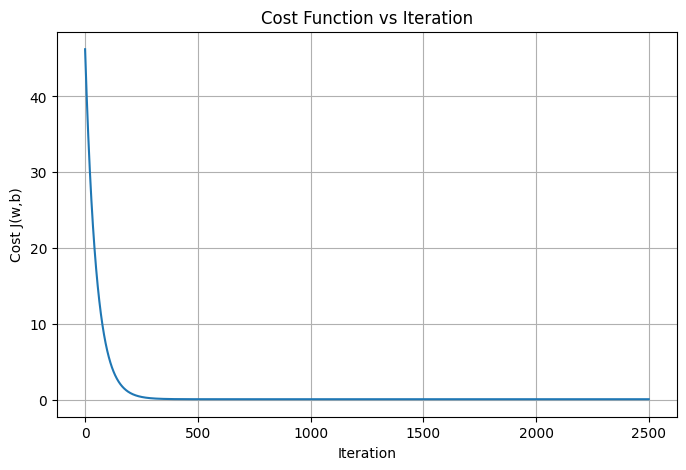

In [324]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Cost J(w,b)")
plt.title("Cost Function vs Iteration")

plt.grid(True)
plt.show()

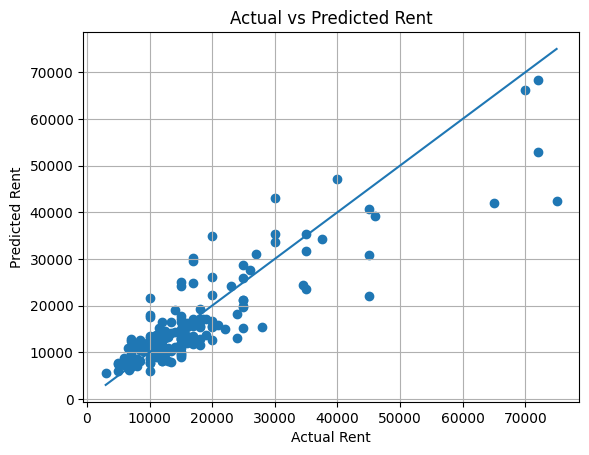

In [325]:
plt.scatter(y_test, test_pred)

minimum = min(y_test.min(), test_pred.min())
maximum = max(y_test.max(), test_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted Rent")
plt.grid()
plt.show()

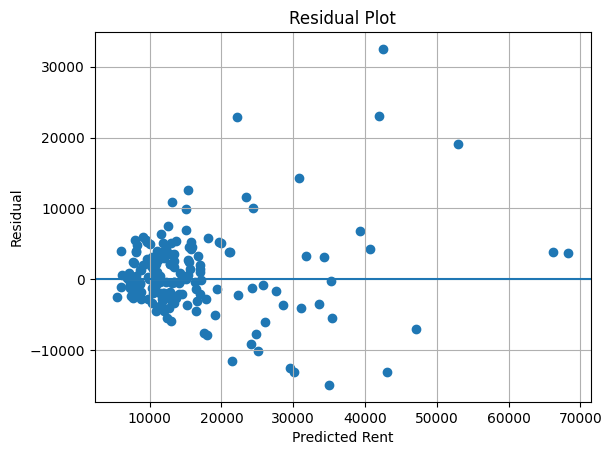

In [326]:
residuals = y_test - test_pred
plt.scatter(test_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Rent")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid()
plt.show()